# Titanic Survival Prediction Using Logistic Regression

**Subject:** Fundamentals of Data Science  
**Case study:** Exploratory data analysis, preprocessing, binary classification, model evaluation, and coefficient interpretation  
**Dataset:** `titanic.csv`

**Student:** Md. Siddiq Juber  
**Roll Number:** 160124733363  
**Section:** CSE-3  
**Faculty:** Smt. S. Durga Devi

---

## 1. Problem statement

The task is to study the supplied Titanic passenger dataset and build a binary classification model that estimates whether a passenger survived (`Survived = 1`) or did not survive (`Survived = 0`). The workflow follows the assignment: EDA, missing-value handling and categorical encoding, logistic-regression training, evaluation using accuracy/precision/recall/F1/ROC-AUC, ROC visualization, feature-coefficient interpretation, and a saved model for a Streamlit app.

This is an educational prediction exercise. The estimated relationships are associations in the recorded data and should not be treated as causal conclusions.


In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
DATA_PATH = ROOT / "titanic.csv"
FIG_DIR = ROOT / "figures"
OUT_DIR = ROOT / "outputs"
MODEL_DIR = ROOT / "models"
for folder in (FIG_DIR, OUT_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET = "Survived"
NUMERIC_FEATURES = ["Age", "SibSp", "Parch", "Fare"]
CATEGORICAL_FEATURES = ["Pclass", "Sex", "Embarked"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

df = pd.read_csv(DATA_PATH)
required_columns = set(FEATURES + [TARGET])
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_required)}")

print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Target column: {TARGET} (0 = did not survive, 1 = survived)")
display(df.head(8))

Dataset shape: 891 rows x 12 columns
Target column: Survived (0 = did not survive, 1 = survived)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S


## 2. Data exploration

The first checks examine dimensions, data types, summary statistics, class balance, and missingness. This establishes the data quality issues that need to be handled before fitting a model.

In [2]:
print("Column data types and non-null counts:")
df.info()

print("\nSummary statistics (numeric columns):")
display(df.describe().T.round(3))

print("\nSummary statistics (categorical and mixed columns):")
display(df.describe(include="all").T)

missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percent": (df.isna().mean() * 100).round(2),
}).sort_values("Missing percent", ascending=False)
print("Missing-value summary:")
display(missing_summary)
missing_summary.to_csv(OUT_DIR / "missing_values.csv")
df.describe(include="all").T.to_csv(OUT_DIR / "descriptive_statistics.csv")

Column data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Summary statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000,257.354,1.00,223.500,446.000,668.5,891.000
Survived,891.0,0.384,0.487,0.00,0.000,0.000,1.0,1.000
Pclass,891.0,2.309,0.836,1.00,2.000,3.000,3.0,3.000
Age,714.0,29.699,14.526,0.42,20.125,28.000,38.0,80.000
SibSp,891.0,0.523,1.103,0.00,0.000,0.000,1.0,8.000
Parch,891.0,0.382,0.806,0.00,0.000,0.000,0.0,6.000
Fare,891.0,32.204,49.693,0.00,7.910,14.454,31.0,512.329



Summary statistics (categorical and mixed columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,1601,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


Missing-value summary:


,Missing count,Missing percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


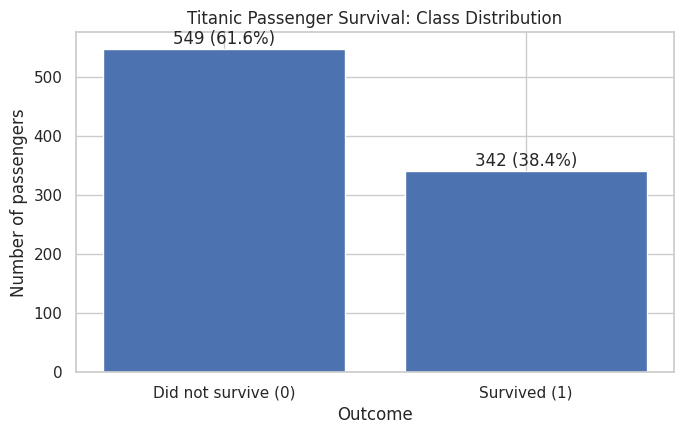

Overall survival rate: 38.4%
Non-survivors: 549 (61.6%)
Survivors: 342 (38.4%)


In [3]:
# Target distribution: counts and percentages
counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4.5))
labels = ["Did not survive (0)", "Survived (1)"]
values = [int(counts.loc[0]), int(counts.loc[1])]
ax.bar(labels, values)
ax.set_title("Titanic Passenger Survival: Class Distribution")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of passengers")
for i, value in enumerate(values):
    ax.text(i, value + 8, f"{value} ({value / len(df):.1%})", ha="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_survival_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Overall survival rate: {df[TARGET].mean():.1%}")
print(f"Non-survivors: {(df[TARGET] == 0).sum()} ({(df[TARGET] == 0).mean():.1%})")
print(f"Survivors: {(df[TARGET] == 1).sum()} ({(df[TARGET] == 1).mean():.1%})")

**Interpretation:** The target contains 549 non-survivors and 342 survivors, so the observed survival rate is 38.4%. The classes are not perfectly balanced; therefore, accuracy alone is not enough to judge the classifier. Precision, recall, F1-score, and ROC-AUC are also reported.

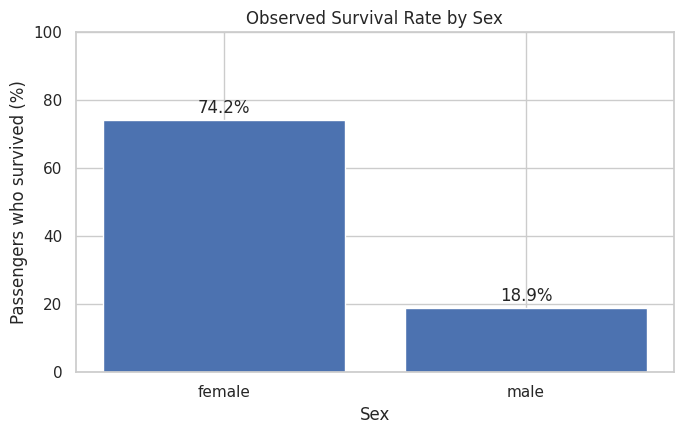

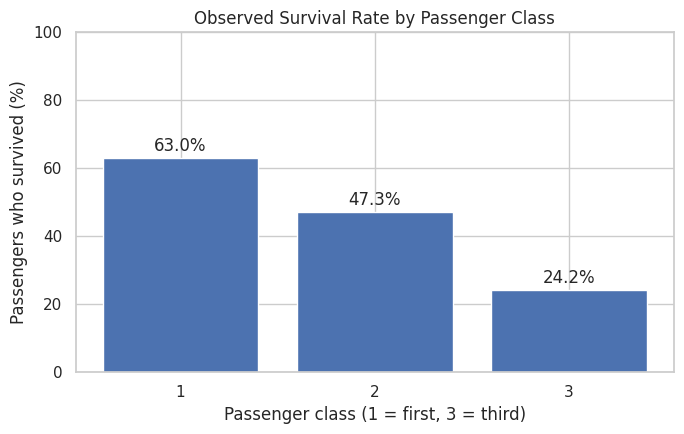

Survival rate by sex:


,Survival rate (%)
Sex,
female,74.20
male,18.89


Survival rate by passenger class:


,Survival rate (%)
Pclass,
1,62.96
2,47.28
3,24.24


In [4]:
# Observed survival percentage by sex
sex_rates = df.groupby("Sex")[TARGET].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(sex_rates.index.astype(str), sex_rates.values * 100)
ax.set_title("Observed Survival Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Passengers who survived (%)")
ax.set_ylim(0, 100)
for i, value in enumerate(sex_rates.values * 100):
    ax.text(i, value + 2, f"{value:.1f}%", ha="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_survival_by_sex.png", dpi=180, bbox_inches="tight")
plt.show()

# Observed survival percentage by class
class_rates = df.groupby("Pclass")[TARGET].mean().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(class_rates.index.astype(str), class_rates.values * 100)
ax.set_title("Observed Survival Rate by Passenger Class")
ax.set_xlabel("Passenger class (1 = first, 3 = third)")
ax.set_ylabel("Passengers who survived (%)")
ax.set_ylim(0, 100)
for i, value in enumerate(class_rates.values * 100):
    ax.text(i, value + 2, f"{value:.1f}%", ha="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_survival_by_class.png", dpi=180, bbox_inches="tight")
plt.show()

print("Survival rate by sex:")
display((sex_rates * 100).rename("Survival rate (%)").round(2).to_frame())
print("Survival rate by passenger class:")
display((class_rates * 100).rename("Survival rate (%)").round(2).to_frame())

**Interpretation:** In this dataset, 74.2% of female passengers survived compared with 18.9% of male passengers. Survival also decreases across passenger class: approximately 63.0% in first class, 47.3% in second class, and 24.2% in third class. These are group-level descriptive patterns, not causal claims.

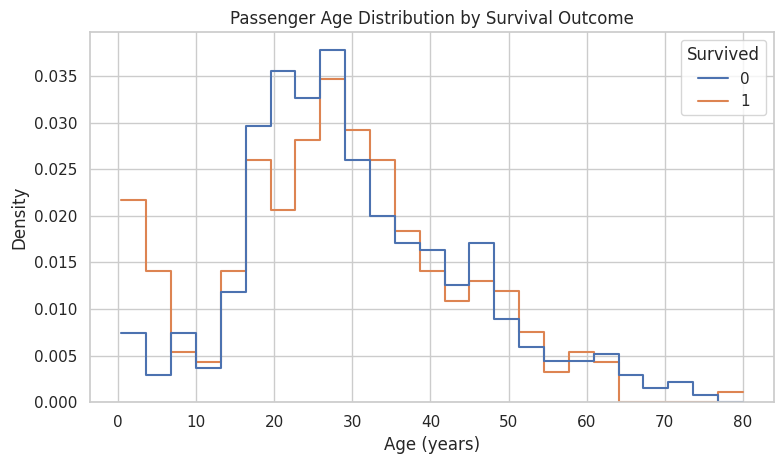

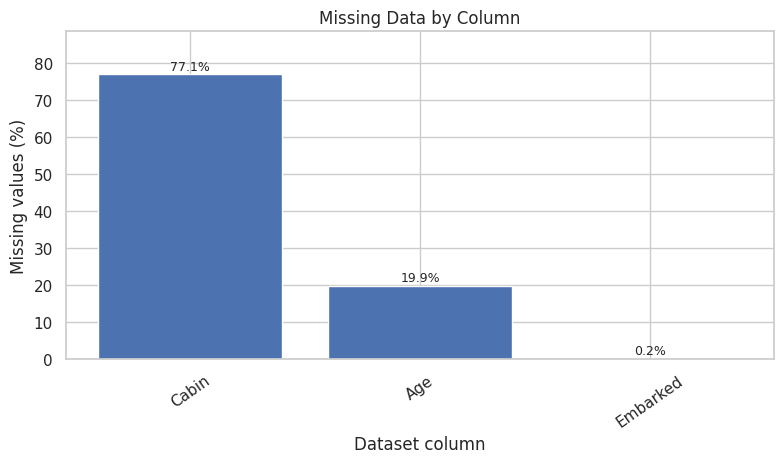

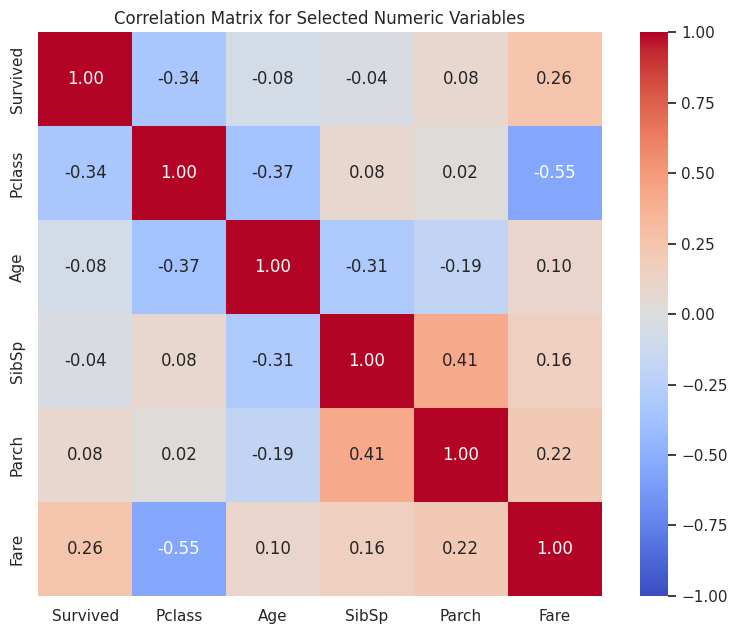

Missing Age: 177
Missing Cabin: 687
Missing Embarked: 2


In [5]:
# Age distribution separated by survival outcome
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(
    data=df, x="Age", hue=TARGET, bins=25, stat="density",
    common_norm=False, element="step", fill=False, ax=ax
)
ax.set_title("Passenger Age Distribution by Survival Outcome")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Density")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_age_distribution_by_survival.png", dpi=180, bbox_inches="tight")
plt.show()

# Missingness plot
missing_percent = df.isna().mean().mul(100).sort_values(ascending=False)
missing_nonzero = missing_percent[missing_percent > 0]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(missing_nonzero.index, missing_nonzero.values)
ax.set_title("Missing Data by Column")
ax.set_xlabel("Dataset column")
ax.set_ylabel("Missing values (%)")
ax.tick_params(axis="x", rotation=35)
for i, value in enumerate(missing_nonzero.values):
    ax.text(i, value + 1.2, f"{value:.1f}%", ha="center", fontsize=9)
ax.set_ylim(0, max(missing_nonzero.values) * 1.15)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_missing_values.png", dpi=180, bbox_inches="tight")
plt.show()

# Correlation matrix for selected numeric variables
correlation_columns = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
fig, ax = plt.subplots(figsize=(8.2, 6.5))
sns.heatmap(
    df[correlation_columns].corr(numeric_only=True), annot=True, fmt=".2f",
    cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax
)
ax.set_title("Correlation Matrix for Selected Numeric Variables")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_correlation_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

print("Missing Age:", int(df["Age"].isna().sum()))
print("Missing Cabin:", int(df["Cabin"].isna().sum()))
print("Missing Embarked:", int(df["Embarked"].isna().sum()))

**Interpretation:** Age is unavailable for 177 passengers, Cabin for 687, and Embarked for 2. Cabin is missing for about 77.1% of rows, so it is not included in this baseline model. The correlation heatmap describes pairwise linear associations among selected numeric columns; it does not establish cause and effect. Age distributions overlap between classes, so age alone would not perfectly separate outcomes.

## 3. Data preprocessing and methodology

The target is `Survived`. The model uses `Age`, `SibSp`, `Parch`, `Fare`, `Pclass`, `Sex`, and `Embarked`. The following columns are omitted from this baseline: `PassengerId` (identifier), `Name` and `Ticket` (high-cardinality text identifiers requiring additional feature engineering), and `Cabin` (very high missingness).

The data is split before fitting preprocessing to avoid using test-set statistics during training. Numeric missing values are replaced with training-set medians and standardized; categorical missing values are replaced by the most frequent training category and encoded with one-hot encoding. Logistic regression is trained with a maximum of 2,000 iterations.

In [6]:
X = df[FEATURES].copy()
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
])
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

model.fit(X_train, y_train)
print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")
print("Features used:", FEATURES)
print("Training completed.")

Training rows: 712
Testing rows: 179
Features used: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked']
Training completed.


## 4. Model evaluation

The test set was held out from model fitting. Predictions use the default probability threshold of 0.50. Accuracy measures the overall fraction of correct predictions; precision measures how many predicted survivors actually survived; recall measures how many actual survivors were identified; F1 is the harmonic mean of precision and recall; ROC-AUC measures the model's ability to rank positive cases above negative cases across thresholds.

In [7]:
y_probability = model.predict_proba(X_test)[:, 1]
y_prediction = (y_probability >= 0.50).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_test, y_prediction),
    "Precision": precision_score(y_test, y_prediction, zero_division=0),
    "Recall": recall_score(y_test, y_prediction, zero_division=0),
    "F1-score": f1_score(y_test, y_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability),
}
metrics_df = pd.DataFrame({"Metric": list(metrics.keys()), "Score": list(metrics.values())})
display(metrics_df.style.format({"Score": "{:.4f}"}))

print("Classification report:")
display(pd.DataFrame(classification_report(
    y_test, y_prediction, output_dict=True, zero_division=0
)).T.round(3))

cm = confusion_matrix(y_test, y_prediction, labels=[0, 1])
print("Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):")
display(pd.DataFrame(cm,
    index=["Actual not survived", "Actual survived"],
    columns=["Predicted not survived", "Predicted survived"]))

metrics_df.to_csv(OUT_DIR / "model_metrics.csv", index=False)

,Metric,Score
0,Accuracy,0.7989
1,Precision,0.7797
2,Recall,0.6667
3,F1-score,0.7188
4,ROC-AUC,0.8436


Classification report:


,precision,recall,f1-score,support
0,0.808,0.882,0.843,110.000
1,0.780,0.667,0.719,69.000
accuracy,0.799,0.799,0.799,0.799
macro avg,0.794,0.774,0.781,179.000
weighted avg,0.797,0.799,0.795,179.000


Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):


,Predicted not survived,Predicted survived
Actual not survived,97,13
Actual survived,23,46


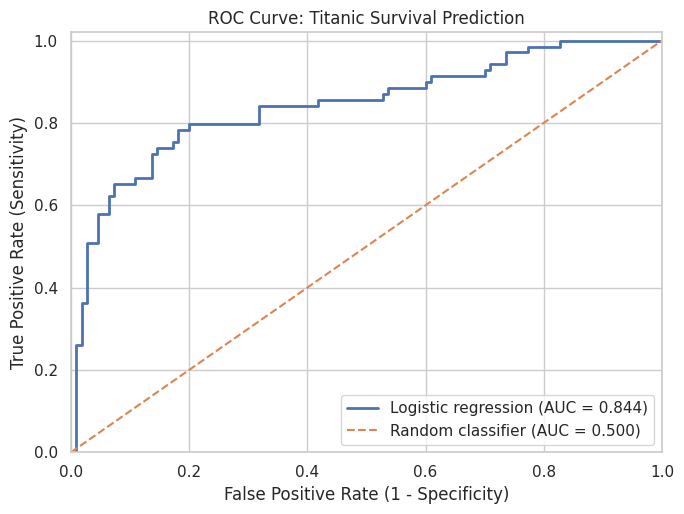

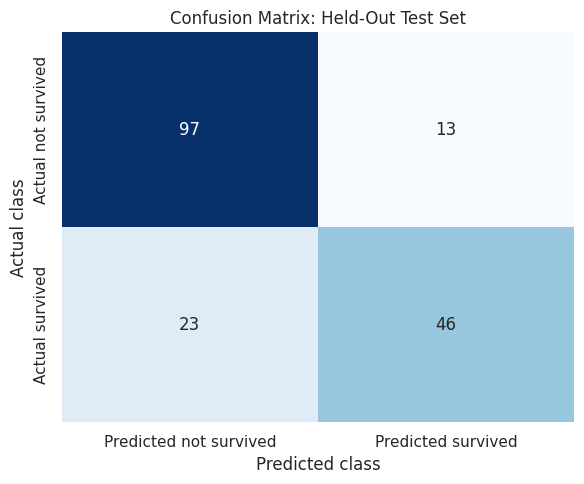

In [8]:
# ROC curve
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_probability)
fig, ax = plt.subplots(figsize=(7, 5.3))
ax.plot(false_positive_rate, true_positive_rate,
        label=f"Logistic regression (AUC = {metrics['ROC-AUC']:.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier (AUC = 0.500)")
ax.set_title("ROC Curve: Titanic Survival Prediction")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_roc_curve.png", dpi=180, bbox_inches="tight")
plt.show()

# Confusion matrix visualization
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted not survived", "Predicted survived"],
            yticklabels=["Actual not survived", "Actual survived"])
ax.set_title("Confusion Matrix: Held-Out Test Set")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

**Interpretation of test performance:** With this fixed split, the model correctly classifies about 79.9% of the test passengers. Its precision is 78.0%, meaning that most passengers predicted to survive did survive in the held-out data. Recall is 66.7%, so it identifies about two-thirds of actual survivors and misses the remainder. The F1-score of 71.9% summarizes the precision-recall balance. ROC-AUC of 0.844 indicates useful ranking ability above the random-classifier reference of 0.500, but it does not mean 84.4% of individual predictions are correct.

The confusion matrix contains 97 true negatives, 13 false positives, 23 false negatives, and 46 true positives. The default 0.50 threshold trades off precision and recall; it could be tuned if the use case assigned a different cost to each error.

## 5. Logistic-regression coefficient interpretation

For a logistic-regression model, a positive coefficient increases the modeled log-odds of survival, while a negative coefficient decreases it, holding the included features constant. Exponentiating a coefficient gives an odds ratio. Numeric inputs were standardized, so their odds ratios correspond to a one-standard-deviation increase, not a one-year or one-currency-unit increase. The one-hot categorical columns use reference categories: first class (`Pclass = 1`), female (`Sex = female`), and Cherbourg (`Embarked = C`).

,Feature,Coefficient,Odds ratio
7,cat__Embarked_Q,0.229,1.257
3,num__Fare,0.175,1.191
2,num__Parch,-0.070,0.932
1,num__SibSp,-0.261,0.770
8,cat__Embarked_S,-0.438,0.645
0,num__Age,-0.469,0.626
4,cat__Pclass_2,-0.735,0.480
5,cat__Pclass_3,-1.920,0.147
6,cat__Sex_male,-2.530,0.080


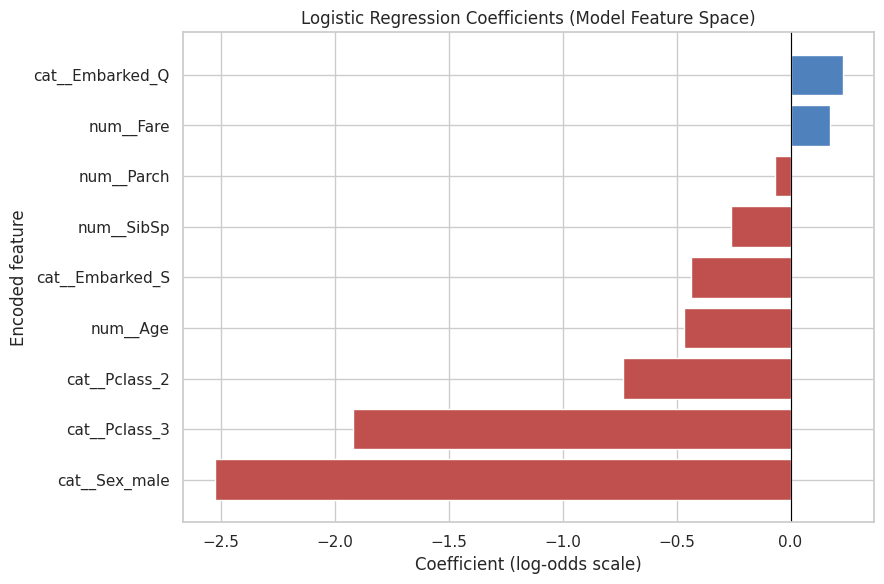

Largest positive and negative coefficients (model feature space):
Positive:


,Feature,Coefficient,Odds ratio
7,cat__Embarked_Q,0.229,1.257
3,num__Fare,0.175,1.191
2,num__Parch,-0.070,0.932
1,num__SibSp,-0.261,0.770
8,cat__Embarked_S,-0.438,0.645


Negative:


,Feature,Coefficient,Odds ratio
6,cat__Sex_male,-2.530,0.080
5,cat__Pclass_3,-1.920,0.147
4,cat__Pclass_2,-0.735,0.480
0,num__Age,-0.469,0.626
8,cat__Embarked_S,-0.438,0.645


In [9]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
coefficient_df = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
coefficient_df["Odds ratio"] = np.exp(coefficient_df["Coefficient"])
coefficient_df["Absolute coefficient"] = coefficient_df["Coefficient"].abs()
coefficient_df = coefficient_df.sort_values("Coefficient", ascending=False)
display(coefficient_df[["Feature", "Coefficient", "Odds ratio"]].round(3))
coefficient_df.to_csv(OUT_DIR / "model_coefficients.csv", index=False)

plot_df = coefficient_df.sort_values("Coefficient")
bar_colors = ["#c0504d" if value < 0 else "#4f81bd" for value in plot_df["Coefficient"]]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df["Feature"], plot_df["Coefficient"], color=bar_colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression Coefficients (Model Feature Space)")
ax.set_xlabel("Coefficient (log-odds scale)")
ax.set_ylabel("Encoded feature")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_model_coefficients.png", dpi=180, bbox_inches="tight")
plt.show()

print("Largest positive and negative coefficients (model feature space):")
print("Positive:")
display(coefficient_df.nlargest(5, "Coefficient")[["Feature", "Coefficient", "Odds ratio"]].round(3))
print("Negative:")
display(coefficient_df.nsmallest(5, "Coefficient")[["Feature", "Coefficient", "Odds ratio"]].round(3))

**Interpretation:** The largest negative coefficient is `Sex_male` (approximately -2.53, odds ratio 0.08), suggesting much lower modeled survival odds for male than female passengers after adjustment for the selected features. `Pclass_3` also has a strongly negative coefficient relative to first class (approximately -1.92, odds ratio 0.15). `Age` has a negative coefficient in standardized units, while `Fare` has a modest positive coefficient. Coefficients depend on model specification and should not be interpreted as causal effects or as standalone measures of statistical significance; this assignment does not include coefficient confidence intervals or hypothesis tests.

## 6. Conclusion and limitations

This case study demonstrates a full tabular binary-classification workflow: inspect the Titanic dataset, explore distributions and observed group differences, impute missing values, scale numerical inputs, encode categorical inputs, fit logistic regression, and evaluate held-out predictions with multiple metrics. On the fixed test split, accuracy is 79.9% and ROC-AUC is 0.844. Sex and passenger class show the strongest associations with the model's predicted survival odds in the fitted feature space.

**Limitations:** the dataset is historical and may contain bias; missing Cabin values are extensive; Name and Ticket are not feature-engineered; performance comes from one random split; and coefficient associations do not establish causation. Cross-validation, threshold tuning, calibration analysis, additional feature engineering, and uncertainty intervals could be future improvements. The Streamlit app loads the saved pipeline and estimates probability for user-entered features; it is a classroom demonstration, not a production or safety-critical system.

In [10]:
# Save reusable model, metrics, and metadata
joblib.dump(model, MODEL_DIR / "titanic_logistic_regression_pipeline.joblib")
metadata = {
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "classification_threshold": 0.50,
    "scikit_learn_version": __import__("sklearn").__version__,
}
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

final_metrics = {
    "dataset_rows": int(len(df)),
    "dataset_columns": int(df.shape[1]),
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "survivors": int(y.sum()),
    "non_survivors": int((y == 0).sum()),
    "survival_rate": float(y.mean()),
    "accuracy": float(metrics["Accuracy"]),
    "precision": float(metrics["Precision"]),
    "recall": float(metrics["Recall"]),
    "f1_score": float(metrics["F1-score"]),
    "roc_auc": float(metrics["ROC-AUC"]),
    "confusion_matrix": cm.tolist(),
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "features": FEATURES,
}
with open(OUT_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(final_metrics, file, indent=2)

print("Saved model:", MODEL_DIR / "titanic_logistic_regression_pipeline.joblib")
print("Saved metrics:", OUT_DIR / "metrics.json")
print("Saved figures:", len(list(FIG_DIR.glob("*.png"))))
print("Analysis complete.")

Saved model: /mnt/data/titanic-logistic-regression-case-study/models/titanic_logistic_regression_pipeline.joblib
Saved metrics: /mnt/data/titanic-logistic-regression-case-study/outputs/metrics.json
Saved figures: 9
Analysis complete.
